# Gravity-mediated entanglement of two trapped particles (after Krisnanda et al. 2020)

T. Krisnanda, G. Y. Tham, M. Paternostro and T. Paterek, *Observable quantum entanglement due to
gravity*, npj Quantum Inf. **6**, 12 (2020), [doi:10.1038/s41534-020-0243-y](https://doi.org/10.1038/s41534-020-0243-y).

Two masses held in harmonic traps a distance $L$ apart attract each other gravitationally. To second
order in the displacements, $-Gm^2/(L + x_B - x_A)$ contains a term $\propto x_Ax_B$, a two-mode
squeezing interaction that can entangle the motions. This notebook uses levisim's interaction layer
(`NewtonianGravity`, `Casimir`, `Coulomb`) with `MultiTrap(interactions=[...])`, the covariance tools
(`levisim.multiphysics.covariance`: the system without the cavity, the exact Lyapunov evolution
$\dot V = AV + VA^\top + D$, the logarithmic negativity between particles) and the decoherence budget
(`levisim.multiphysics.decoherence.decoherence_budget`) to

1. reproduce the paper's figure of merit $\eta = 2Gm/(\omega^2L^3)$ and its analytic results for
   trapped masses: the maximum entanglement from the ground state, from thermal states and from
   squeezed states,
2. compare gravity with the interactions that compete with it: Casimir attraction and the Coulomb
   force of residual charges,
3. scan separation, size, pressure and temperature to show where gravitationally generated Gaussian
   entanglement ($E_N > 0$) survives gas collisions and blackbody radiation.

**Scope.** levisim models Gaussian (linearised) states of harmonic motion. The spin-superposition
protocol of Bose et al., Phys. Rev. Lett. **119**, 240401 (2017), which needs a spin degree of
freedom and macroscopic spatial superpositions, is out of scope. So is the paper's second scheme with
masses released from their traps. Logarithmic negativities are given in natural units (nats). The
paper uses base 2, so its $\eta/\ln 2$ bits are $\eta$ nats.

Runtime: about half a minute.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from levisim.core.constants import π, e, ħ, c, kB
from levisim.core.units import mbar
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics.material import Material
from levisim.physics.materials import FUSED_SILICA
from levisim.physics.particle import Sphere
from levisim.physics.interactions import NewtonianGravity, Casimir, Coulomb, G_newton
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.covariance import (
    evolve_covariance, particle_log_negativity, product_state_covariance,
)
from levisim.multiphysics.decoherence import decoherence_budget

set_plt_rcParams_to_xmgrace_style()
logger.remove()  # the scans build hundreds of systems; their INFO/WARNING lines are not needed here
T_START = time.time()

OSMIUM = Material('osmium', ρ=22590.0, permittivity=4.0, notes='density only; Krisnanda et al. 2020')


def gravity_pair(R, L_over_R, Ω, P=0.0, T=300.0, material=OSMIUM):
    # two equal spheres a distance L apart along x, each in a harmonic trap of frequency Ω (x only),
    # coupled by Newtonian gravity; the cavity is not used (cavity=False below)
    particles = [Sphere(r=R, material=material), Sphere(r=R, material=material)]
    return MultiTrap(
        num_traps=2, Cartesian_axes_per_trap=1, beads=particles,
        trap_positions=[(0, 0, 0), (L_over_R * R, 0, 0)],
        trap_kwargs=[{'override_Ω_dict': {'x': Ω, 'y': Ω, 'z': Ω}}] * 2,
        interactions=[NewtonianGravity()], gas_kwargs={'P': P, 'T': T},
        photon_recoil=False, static_cavity_shifts=False,
    )


def figure_of_merit(mtrap, Ω):
    m, L = mtrap.traps[0].bead.m, mtrap.traps[1].position[0]
    return 2 * G_newton * m / (Ω**2 * L**3)


def maximum_entanglement(mtrap, Ω, n0=0.0, squeezing=None, heating=True, T_environment=None, periods=0.6, points=200):
    # largest E_N between the particles over 0 ≤ t ≤ periods·2π/Ω, from a product state of
    # occupation n0; heating=True adds the blackbody rates of the decoherence budget to the gas bath
    extra = None
    if heating:
        budget = decoherence_budget(mtrap, T_environment=T_environment)
        extra = budget.extra_heating(exclude=('gas', 'photon_recoil'))
    times = np.linspace(0, periods * 2 * π / Ω, points)
    V0 = product_state_covariance(mtrap, n0, cavity=False, squeezing=squeezing)
    V = evolve_covariance(mtrap, V0, times, cavity=False, extra_heating=extra)
    E = particle_log_negativity(mtrap, V, 1, cavity=False)
    return E.max(), times, E

## 1. The trapped-mass results of the paper

For two spheres of density $\rho$ a distance $L = 2.1R$ apart (the paper's choice), $\eta =
8\pi G\rho/(3\cdot2.1^3\omega^2)$, which for osmium ($\rho$ = 22.59 g/cm³) the paper gives as
$1.36\times10^{-6}/\omega^2$. `MultiTrap` linearises gravity at the trap positions. The self term
softens each trap, $\Omega^2 = \omega^2(1 - \eta)$, and the cross term becomes the coupling rate
$g_{12} = -K_{12}x_\mathrm{zpf}^2/\hbar$. This is the paper's Eq. (4). Without damping the paper
finds that the ground state reaches $E_N^\mathrm{max} \approx \eta$ at $\omega t = \pi/2(1 - \eta)$,
thermal states of occupation $n$ reach $\eta - \ln(2n + 1)$, and squeezed states with $s_A, s_B
\gg \eta$ reach $|s_A + s_B|$ at $t = \pi/(2\eta\omega)$. Here $\omega = 0.01$ s⁻¹, so that
$\eta$ = 0.0136 is large enough to see.

η·ω² = 1.364e-06 s⁻² (paper: 1.36e-6); η = 0.01364 at ω = 0.01 s⁻¹
Ω/ω = 0.993157 (√(1 - η) = 0.993157); g12/ω = -0.006866
ground state: E_N,max = 0.013827 nats (0.019948 bits) at ωt = 1.5826; paper ≈ η = 0.013639 at ωt = 1.5925
thermal n = 0.001: E_N,max = 0.011829, paper η - ln(2n+1) = 0.011641
thermal n = 0.003: E_N,max = 0.007845, paper η - ln(2n+1) = 0.007657
thermal n = 0.006: E_N,max = 0.001898, paper η - ln(2n+1) = 0.001710
squeezed s = 0.5 at θ = 0.000: E_N,max = 1.0068, paper |sA + sB| = 1.0
squeezed s = 0.5 at θ = 0.785: E_N,max = 1.0068, paper |sA + sB| = 1.0


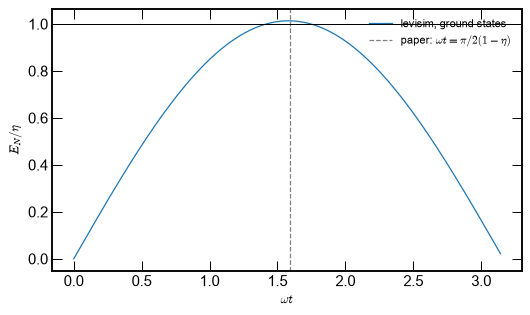

In [2]:
ω = 0.01
R = 1e-3
mtrap = gravity_pair(R, 2.1, ω, P=0.0)
η = figure_of_merit(mtrap, ω)
print(f'η·ω² = {η * ω**2:.4g} s⁻² (paper: 1.36e-6); η = {η:.5f} at ω = {ω} s⁻¹')
print(f'Ω/ω = {mtrap.dimensions["x1"].Ω / ω:.6f} (√(1 - η) = {np.sqrt(1 - η):.6f}); g12/ω = {mtrap.mechanical_coupling_matrix[0, 1] / ω:.6f}')

E_max, times, E = maximum_entanglement(mtrap, ω, heating=False, periods=0.5, points=801)
t_star = π / (2 * (1 - η) * ω)
print(f'ground state: E_N,max = {E_max:.6f} nats ({E_max / np.log(2):.6f} bits) at ωt = {ω * times[np.argmax(E)]:.4f};'
      f' paper ≈ η = {η:.6f} at ωt = {ω * t_star:.4f}')
rows = []
for n in (0.001, 0.003, 0.006):
    E_n = maximum_entanglement(mtrap, ω, n0=n, heating=False, periods=0.5, points=801)[0]
    rows.append((n, E_n, η - np.log(2 * n + 1)))
    print(f'thermal n = {n}: E_N,max = {E_n:.6f}, paper η - ln(2n+1) = {η - np.log(2 * n + 1):.6f}')
s = 0.5
for θ in (0.0, π / 4):
    E_s, t_s, _ = maximum_entanglement(mtrap, ω, squeezing={'x1': (s, θ), 'x2': (s, θ)}, heating=False,
                                       periods=1 / (2 * η), points=2001)
    print(f'squeezed s = {s} at θ = {θ:.3f}: E_N,max = {E_s:.4f}, paper |sA + sB| = {2 * s}')

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(ω * times, E / η, label='levisim, ground states')
ax.axvline(ω * t_star, color='grey', ls='--', lw=1, label=r'paper: $\omega t = \pi/2(1-\eta)$')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel(r'$\omega t$')
ax.set_ylabel(r'$E_N/\eta$')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

With the frequency shift included, levisim's model is exactly the paper's Eq. (4), and the
analytic statements hold to the order to which the paper derived them. The ground-state maximum
exceeds $\eta$ by about $\eta$ itself (1.4 % here), an $O(\eta^2)$ term the leading-order formula
leaves out. The thermal amplitudes agree to $O(\eta^2)$. The squeezed maxima are within 1 % of
$|s_A + s_B|$ and do not depend on the squeezing direction, as the paper states.

## 2. Competing interactions

Gravity has to win against the other forces between the particles. The coupling stiffness along the
line of centres is $K_{12} = -U''(L)$. For gravity it is $2Gm^2/L^3$. A single elementary charge on
each particle gives $2e^2/(4\pi\varepsilon_0L^3)$, which equals gravity at $m$ = 1.86 μg
independently of $L$. For the Casimir attraction, `Casimir(model='casimir_polder')` ($\propto r^{-7}$)
applies far apart and `Casimir(model='proximity_force')` ($\propto$ gap$^{-2}$) at small gaps. Both
use the static permittivity (here 3.8, fused silica, for the Lifshitz factor, and the ideal-mirror
upper bound for a metal such as osmium) and are zero-temperature results, valid below the thermal
wavelength.

osmium, m = 1 kg (R = 21.94 mm), L = 2.1R: Casimir/gravity coupling = 2.8e-12 (paper r_cg ~1e-12); gap 2.19 mm, gap/R = 0.1, thermal wavelength at 4 K = 0.57 mm
osmium, m = 1e-07 kg (R = 0.10 mm), L = 3.0R: Casimir/gravity coupling = 0.083 (paper r_cg ~1e-2); gap 0.10 mm, gap/R = 1.0, thermal wavelength at 4 K = 0.57 mm


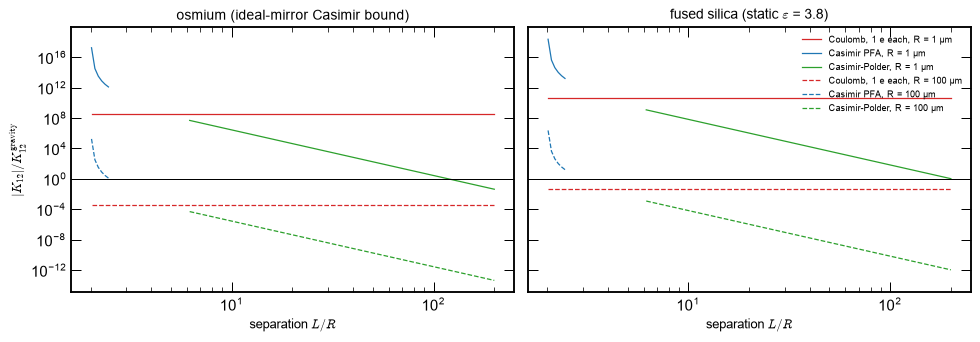

In [3]:
def coupling_stiffness(interaction, R, L_over_R, material, charge=0):
    particles = [Sphere(r=R, material=material, charge=charge) for _ in range(2)]
    positions = np.array([[0.0, 0.0, 0.0], [L_over_R * R, 0.0, 0.0]])
    return abs(interaction.stiffness_blocks(positions, particles)[0, 1, 0, 0])


L_over_R = np.geomspace(2.02, 200, 120)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, (material, label, casimir_kwargs) in zip(axes, (
        (OSMIUM, 'osmium (ideal-mirror Casimir bound)', dict(ideal_mirrors=True)),
        (FUSED_SILICA, r'fused silica (static $\varepsilon$ = 3.8)', dict(permittivity=3.8)))):
    for R, style in ((1e-6, '-'), (1e-4, '--')):
        gravity = np.array([coupling_stiffness(NewtonianGravity(), R, x, material) for x in L_over_R])
        coulomb = np.array([coupling_stiffness(Coulomb(), R, x, material, charge=1) for x in L_over_R])
        pfa = np.array([coupling_stiffness(Casimir(model='proximity_force', validity_warning_ratio=0, **casimir_kwargs), R, x, material)
                        for x in L_over_R])
        cp = np.array([coupling_stiffness(Casimir(permittivity=3.8 if material is FUSED_SILICA else 1e6,
                                                  validity_warning_ratio=0), R, x, material) for x in L_over_R])
        near, far = L_over_R < 2.5, L_over_R > 6
        ax.loglog(L_over_R, coulomb / gravity, 'C3' + style, label=f'Coulomb, 1 e each, R = {R*1e6:g} μm')
        ax.loglog(L_over_R[near], pfa[near] / gravity[near], 'C0' + style, label=f'Casimir PFA, R = {R*1e6:g} μm')
        ax.loglog(L_over_R[far], cp[far] / gravity[far], 'C2' + style, label=f'Casimir-Polder, R = {R*1e6:g} μm')
    ax.axhline(1, color='k', lw=0.8)
    ax.set_xlabel(r'separation $L/R$')
    ax.set_title(label, fontsize=11)
axes[0].set_ylabel(r'$|K_{12}|/K_{12}^\mathrm{gravity}$')
axes[1].legend(frameon=False, fontsize=7.5, loc='upper right')
fig.tight_layout()
plt.show()

# the paper's Casimir-to-gravity ratios r_cg (ideal-mirror PFA, f0 = 1, as an upper bound)
for m_kg, x, quoted in ((1.0, 2.1, '~1e-12'), (100e-9, 3.0, '~1e-2')):
    R_m = (3 * m_kg / (4 * π * OSMIUM.ρ))**(1 / 3)
    ratio = (coupling_stiffness(Casimir(model='proximity_force', ideal_mirrors=True, validity_warning_ratio=0), R_m, x, OSMIUM)
             / coupling_stiffness(NewtonianGravity(), R_m, x, OSMIUM))
    gap = (x - 2) * R_m
    print(f'osmium, m = {m_kg:g} kg (R = {R_m*1e3:.2f} mm), L = {x}R: Casimir/gravity coupling = {ratio:.2g}'
          f' (paper r_cg {quoted}); gap {gap*1e3:.2f} mm, gap/R = {x - 2:.1f},'
          f' thermal wavelength at 4 K = {ħ * c / (kB * 4) * 1e3:.2f} mm')

For the paper's 1 kg osmium spheres at $L = 2.1R$, the proximity-force Casimir coupling is
$2.8\times10^{-12}$ of the gravitational one, as the paper's $r_\mathrm{cg}\sim10^{-12}$. For the 100 μg
spheres at $L = 3R$ ($R$ = 0.10 mm, gap = $R$) it is 0.083, against the paper's $\sim10^{-2}$. The paper
takes an unspecified fraction $0 \le f_0 \le 1$ of the proximity-force energy (here $f_0 = 1$, ideal
mirrors, an upper bound), and a gap equal to the radius is outside the proximity-force regime. The 1 kg
gap (2.2 mm) also exceeds the 4 K thermal wavelength (0.57 mm), where the zero-temperature result no
longer holds. Both are order-of-magnitude comparisons. For micron-sized particles, Casimir dominates
gravity within a few radii, and the Coulomb force of a single elementary charge dominates at every
separation for masses below 1.86 μg ($R$ ≈ 27 μm for osmium, 59 μm for fused silica). Gravity-mediated entanglement of small particles needs
both suppressed: neutral particles, and separations of many radii or screening (van de Kamp et al.,
Phys. Rev. A **102**, 062807 (2020)). The scans below include gravity only.

## 3. Decoherence: where does the entanglement survive?

Each particle exchanges heat with the gas (levisim's bath, $\Gamma_\mathrm{gas}n_\mathrm{th}$) and with
thermal radiation (`decoherence_budget`: blackbody scattering, emission and absorption from
Romero-Isart, Phys. Rev. A **84**, 052121 (2011), Eqs. (28)-(29), with the silica $\varepsilon_\mathrm{bb}$ =
2.1 + 0.57i of its Table III and the particle at the environment's temperature). Photon recoil is left
out (these are not optical traps), and so are electrode noise (neutral particles) and the Casimir and
Coulomb couplings. The figure of merit is $E_N^\mathrm{max}/\eta$, the largest entanglement over the
first 0.6 trap periods from the ground state, relative to the noiseless value.

In the weak-coupling regime ($\eta \ll 1$) the result does not depend on the trap frequency. $\eta
\propto 1/\Omega^2$, and so is the noise accumulated over the entangling time $\sim\pi/2\Omega$: every
heating rate here scales as $1/\Omega$ (thermal occupation $\propto 1/\Omega$, localisation heating
$2\Lambda x_\mathrm{zpf}^2 \propto 1/\Omega$). The scans use $\Omega$ = 0.04 s⁻¹, where $\eta \approx
8.5\times10^{-4}$ for osmium at $L = 2.1R$, and the next cell checks the invariance at $\Omega$ = 0.12 s⁻¹.

In [4]:
Ω_scan = 0.04
example = gravity_pair(10e-6, 2.1, Ω_scan, P=1e-20 * mbar, T=1.0)
budget = decoherence_budget(example, T_environment=1.0)
print(f'R = 10 μm osmium, L = 2.1R, P = 1e-20 mbar, T = 1 K, Ω = {Ω_scan} s⁻¹ (η = {figure_of_merit(example, Ω_scan):.3g}):')
print(budget.table())

def noiseless(R, L_over_R, Ω):
    # the same pair without gas (Γ = 0) and without blackbody radiation
    return maximum_entanglement(gravity_pair(R, L_over_R, Ω, P=0.0), Ω, heating=False, points=120)[0]


for P in (1e-21, 1e-22, 1e-23):
    ratios = []
    for Ω in (Ω_scan, 3 * Ω_scan):
        m = gravity_pair(10e-6, 2.1, Ω, P=P * mbar, T=1.0)
        ratios.append(maximum_entanglement(m, Ω, T_environment=1.0, points=120)[0] / noiseless(10e-6, 2.1, Ω))
    print(f'P = {P:g} mbar: E_N,max/E_N,max(noiseless) = {ratios[0]:.4f} at Ω = {Ω_scan}, {ratios[1]:.4f} at Ω = {3 * Ω_scan} s⁻¹')

R = 10 μm osmium, L = 2.1R, P = 1e-20 mbar, T = 1 K, Ω = 0.04 s⁻¹ (η = 0.000852):
  mode                   gas         photon_recoil  blackbody_scattering    blackbody_emission  blackbody_absorption  electric_field_noise                 total
    x1               1.9e-06               0.03723             4.393e-18             1.499e-13             1.499e-13                     0               0.03724
    x2               1.9e-06               0.03698             4.393e-18             1.499e-13             1.499e-13                     0               0.03698
P = 1e-21 mbar: E_N,max/E_N,max(noiseless) = 0.9826 at Ω = 0.04, 0.9826 at Ω = 0.12 s⁻¹
P = 1e-22 mbar: E_N,max/E_N,max(noiseless) = 0.9982 at Ω = 0.04, 0.9982 at Ω = 0.12 s⁻¹
P = 1e-23 mbar: E_N,max/E_N,max(noiseless) = 0.9998 at Ω = 0.04, 0.9998 at Ω = 0.12 s⁻¹


R = 10 μm, T = 0.01 K: E_N > 10⁻³ of noiseless up to 4.6e-19 mbar, half up to 2.2e-19 mbar
R = 10 μm, T = 0.0911 K: E_N > 10⁻³ of noiseless up to 2.2e-19 mbar, half up to 1.0e-19 mbar
R = 10 μm, T = 0.829 K: E_N > 10⁻³ of noiseless up to 4.6e-20 mbar, half up to 2.2e-20 mbar
R = 10 μm, T = 3.62 K: E_N > 10⁻³ of noiseless up to 4.6e-20 mbar, half up to 1.0e-20 mbar
R = 10 μm, T = 10.9 K: E_N > 10⁻³ of noiseless up to 2.2e-20 mbar, half up to 4.6e-21 mbar
R = 1 μm, T = 1 K: E_N > 10⁻³ of noiseless up to 4.6e-21 mbar, half up to 2.2e-21 mbar
R = 10 μm, T = 1 K: E_N > 10⁻³ of noiseless up to 4.6e-20 mbar, half up to 2.2e-20 mbar
R = 100 μm, T = 1 K: E_N > 10⁻³ of noiseless up to 4.6e-19 mbar, half up to 2.2e-19 mbar
R = 1e+03 μm, T = 1 K: E_N > 10⁻³ of noiseless up to 4.6e-18 mbar, half up to 2.2e-18 mbar
computation time 15.7 s


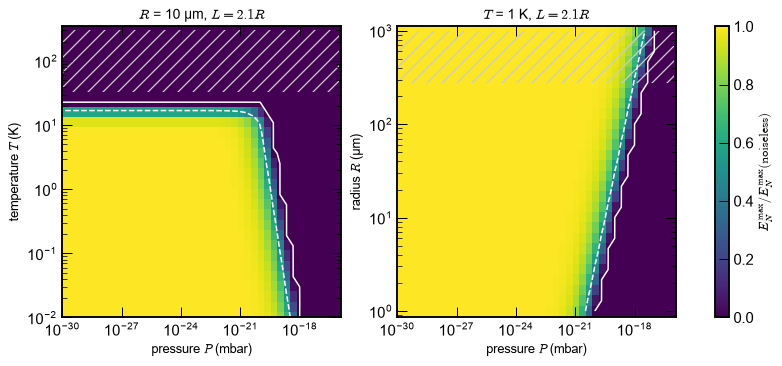

In [5]:
reference = {}


def survival(R, L_over_R, P, T):
    if (R, L_over_R) not in reference:
        reference[(R, L_over_R)] = noiseless(R, L_over_R, Ω_scan)
    m = gravity_pair(R, L_over_R, Ω_scan, P=P * mbar, T=T)
    return maximum_entanglement(m, Ω_scan, T_environment=T, points=120)[0] / reference[(R, L_over_R)]


def size_parameter(R, T):
    # R·kB·T/(ħc): the blackbody rates are point-dipole results, valid well below 0.1
    return R * kB * T / (ħ * c)


pressures = np.geomspace(1e-30, 1e-16, 43)        # [mbar]
temperatures = np.geomspace(0.01, 300, 29)        # [K]
radii = np.geomspace(1e-6, 1e-3, 28)              # [m]

map_PT = np.array([[survival(10e-6, 2.1, P, T) for P in pressures] for T in temperatures])
map_RP = np.array([[survival(R, 2.1, P, 1.0) for P in pressures] for R in radii])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, data, y, ylabel, title, invalid in (
        (axes[0], map_PT, temperatures, 'temperature $T$ (K)', r'$R$ = 10 μm, $L = 2.1R$',
         size_parameter(10e-6, temperatures) > 0.1),
        (axes[1], map_RP, radii * 1e6, r'radius $R$ (μm)', r'$T$ = 1 K, $L = 2.1R$',
         size_parameter(radii, 1.0) > 0.1)):
    mesh = ax.pcolormesh(pressures, y, np.clip(data, 0, 1), cmap='viridis', vmin=0, vmax=1, shading='nearest')
    ax.contour(pressures, y, data, levels=[1e-3, 0.5], colors=['w', 'w'], linestyles=['-', '--'], linewidths=1.2)
    if np.any(invalid):
        ax.fill_between(pressures, y[invalid].min(), y.max(), hatch='//', facecolor='none', edgecolor='0.8', lw=0)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('pressure $P$ (mbar)')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11)
fig.colorbar(mesh, ax=axes, label=r'$E_N^\mathrm{max}/E_N^\mathrm{max}(\mathrm{noiseless})$')
plt.show()

def highest_pressure(row, threshold):
    # the highest pressure of the grid at which the ratio is above the threshold (None if none)
    above = pressures[row > threshold]
    return f'{above.max():.1e} mbar' if len(above) else 'none in the grid'


for T in (0.01, 0.1, 1.0, 4.0, 10.0):
    row = map_PT[np.argmin(np.abs(temperatures - T))]
    print(f'R = 10 μm, T = {temperatures[np.argmin(np.abs(temperatures - T))]:.3g} K: E_N > 10⁻³ of noiseless up to'
          f' {highest_pressure(row, 1e-3)}, half up to {highest_pressure(row, 0.5)}')
for R in (1e-6, 1e-5, 1e-4, 1e-3):
    row = map_RP[np.argmin(np.abs(radii - R))]
    print(f'R = {radii[np.argmin(np.abs(radii - R))]*1e6:.3g} μm, T = 1 K: E_N > 10⁻³ of noiseless up to'
          f' {highest_pressure(row, 1e-3)}, half up to {highest_pressure(row, 0.5)}')
print(f'computation time {time.time() - T_START:.1f} s')

White lines: $E_N^\mathrm{max}$ above 10⁻³ of its noiseless value (solid) and above half of it
(dashed). The hatched region is where the blackbody rates leave their point-dipole validity
($Rk_BT/\hbar c > 0.1$) and overestimate the heating. The noise accumulated over the entangling time
scales as $\Gamma_\mathrm{gas}k_BT/\hbar \propto P\sqrt{T}/(\rho R)$ against $\eta \propto G\rho$. The
tolerable pressure therefore grows in proportion to the radius: at 1 K, half of the noiseless
entanglement survives up to 2.2 × 10⁻²¹, 2.2 × 10⁻²⁰ and 2.2 × 10⁻¹⁹ mbar for $R$ = 1, 10 and 100 μm.
It grows slowly towards low temperature. Blackbody scattering ($\propto R^6T^9$) closes the window
above about 15 K for 10 μm spheres. Every pressure here is many orders of magnitude below what
cryogenic vacuum systems reach ($\sim10^{-14}$-$10^{-17}$ mbar). That is the paper's conclusion for
trapped masses: in harmonic traps the Gaussian entanglement $\approx\eta$ that gravity generates from
the ground state is too small to survive realistic decoherence. It needs very large masses at very low
frequencies (LIGO-like mirrors), strongly squeezed initial states, or the released-mass scheme.

## Summary

**Agreements with Krisnanda et al. (2020)**

- $\eta\omega^2 = 1.364\times10^{-6}$ s⁻² for osmium at $L = 2.1R$ (paper $1.36\times10^{-6}$).
- Without damping: the ground state reaches $E_N^\mathrm{max}$ = 0.013827 nats against the paper's
  $\approx\eta$ = 0.013639 (an $O(\eta^2)$ difference), at $\omega t$ = 1.583 against
  $\pi/2(1 - \eta)$ = 1.593. Thermal states reach $\eta - \ln(2n+1)$ to the same $O(\eta^2)$. Squeezed states
  ($s$ = 0.5) reach 1.0068 against $|s_A + s_B|$ = 1, for both squeezing directions tried.
- Casimir-to-gravity coupling for 1 kg osmium spheres at $2.1R$: $2.8\times10^{-12}$ (paper $\sim10^{-12}$).

**Differences and limits**

- For 100 μg spheres at $L = 3R$ the Casimir ratio is 0.083 (paper $\sim10^{-2}$). The paper's $f_0$ is
  unspecified, and the gap is outside the proximity-force regime.
- The paper's coherence times (from superposition sizes) and its released-mass scheme are not
  reproduced. levisim's decoherence enters as heating of the harmonic modes.
- The survival maps are in the weak-coupling regime ($\eta \ll 1$), where they do not depend on the trap
  frequency (checked at two frequencies). They assume ground-state initial states and include gravity
  only.
- Gaussian states only, so Bose et al. (2017) is out of scope. The blackbody rates are point-dipole
  results, and the gas heating is levisim's bath (free-molecular damping).